<a href="https://colab.research.google.com/github/jluzande/computer-vision-projects/blob/main/lab1_image_manipulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== PART 1: IMAGE PROPERTIES ===
Height (Rows):     512 px
Width (Columns):   512 px
Color Channels:    3
OpenCV uses BGR format (Blue, Green, Red) by default.

Original Color Image:


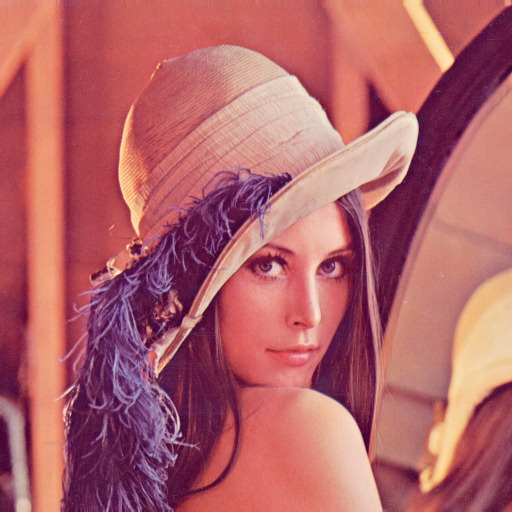


Grayscale Dimensions: (512, 512) (Single channel intensity 0–255)
Grayscale Image:


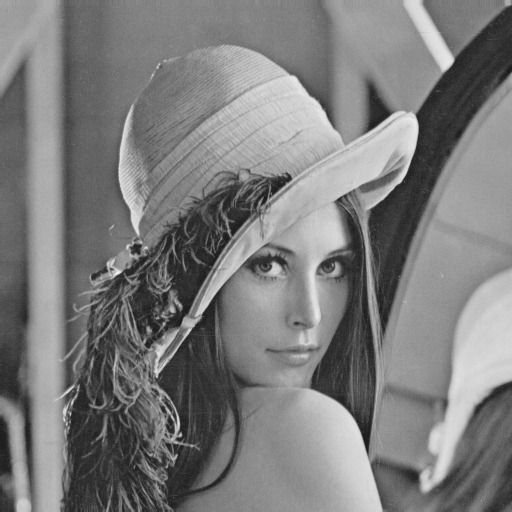


Original BGR at (x=256, y=256): [ 74  65 181]
Modified Pixel Patch (Center Red Square):


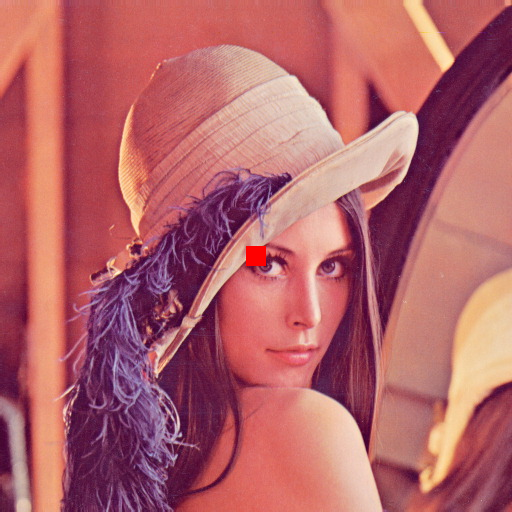


=== PART 2: BASIC IMAGE OPERATIONS ===
1. Cropped ROI:


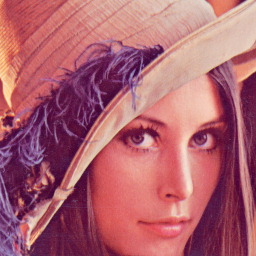


2. Resized Down (50% - 256x256):


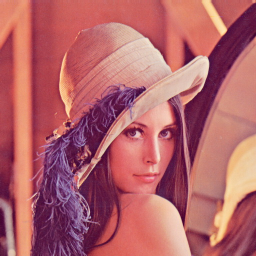


3. Rotated 90 Degrees Clockwise:


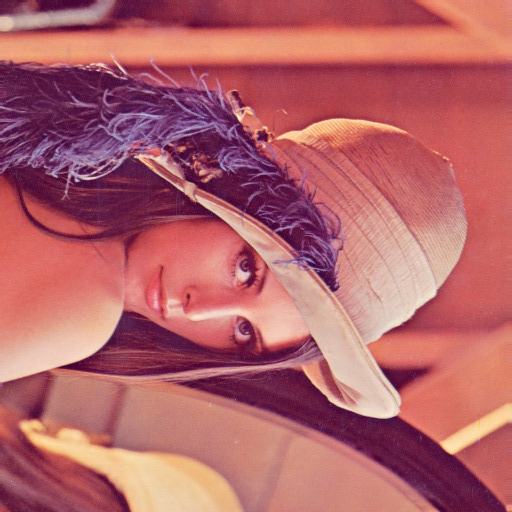


All output images have been saved to your Colab files tab for easy download.


In [1]:
# ==========================================================
# CSST106 - Laboratory Exercise 1 (Google Colab Version)
# ==========================================================

import cv2
import numpy as np
import urllib.request
from google.colab.patches import cv2_imshow

# 1. Download a sample image directly into Colab
sample_url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
image_path = "sample.jpg"
urllib.request.urlretrieve(sample_url, image_path)

# ==========================================================
# PART 1: UNDERSTANDING DIGITAL IMAGES
# ==========================================================

# Load the color image
color_img = cv2.imread(image_path)
height, width, channels = color_img.shape

print("=== PART 1: IMAGE PROPERTIES ===")
print(f"Height (Rows):     {height} px")
print(f"Width (Columns):   {width} px")
print(f"Color Channels:    {channels}")
print("OpenCV uses BGR format (Blue, Green, Red) by default.\n")

print("Original Color Image:")
cv2_imshow(color_img)

# Convert to Grayscale
gray_img = cv2.cvtColor(color_img, cv2.COLOR_BGR2GRAY)
print(f"\nGrayscale Dimensions: {gray_img.shape} (Single channel intensity 0–255)")
print("Grayscale Image:")
cv2_imshow(gray_img)

# Examine & Modify Specific Pixels
target_y, target_x = height // 2, width // 2
print(f"\nOriginal BGR at (x={target_x}, y={target_y}): {color_img[target_y, target_x]}")

# Create a copy and draw a noticeable 20x20 red square patch [B=0, G=0, R=255]
pixel_mod_img = color_img.copy()
pixel_mod_img[target_y - 10:target_y + 10, target_x - 10:target_x + 10] = [0, 0, 255]

print("Modified Pixel Patch (Center Red Square):")
cv2_imshow(pixel_mod_img)

# ==========================================================
# PART 2: BASIC IMAGE OPERATIONS
# ==========================================================
print("\n=== PART 2: BASIC IMAGE OPERATIONS ===")

# 1. Crop a Region of Interest (ROI) - Center 50%
roi_y1, roi_y2 = int(height * 0.25), int(height * 0.75)
roi_x1, roi_x2 = int(width * 0.25), int(width * 0.75)
cropped_roi = color_img[roi_y1:roi_y2, roi_x1:roi_x2]

print("1. Cropped ROI:")
cv2_imshow(cropped_roi)

# 2. Resize Image
# Downscale by 50%
resized_small = cv2.resize(color_img, (width // 2, height // 2), interpolation=cv2.INTER_AREA)
print(f"\n2. Resized Down (50% - {resized_small.shape[1]}x{resized_small.shape[0]}):")
cv2_imshow(resized_small)

# 3. Rotate Image by 90 Degrees Clockwise
rotated_90 = cv2.rotate(color_img, cv2.ROTATE_90_CLOCKWISE)
print("\n3. Rotated 90 Degrees Clockwise:")
cv2_imshow(rotated_90)

# ==========================================================
# SAVE ARTIFACTS FOR REPORT SCREENSHOTS
# ==========================================================
cv2.imwrite("output_original.png", color_img)
cv2.imwrite("output_grayscale.png", gray_img)
cv2.imwrite("output_pixel_mod.png", pixel_mod_img)
cv2.imwrite("output_cropped.png", cropped_roi)
cv2.imwrite("output_resized.png", resized_small)
cv2.imwrite("output_rotated.png", rotated_90)

print("\nAll output images have been saved to your Colab files tab for easy download.")